![Banner](../../../../Images/Banner/07_remote_sensing/09_03_banner_rs_rader.png)


# Dual-Pol Polarimetric Decomposition (SLC)

This notebook explains the dual-pol (VV and VH) polarimetric decomposition of Sentinel-1 SLC data into entropy, anisotropy and alpha angle, and computes it on a real scene of the Teknaf coast in Cox's Bazar, Bangladesh.


## Overview

Dual-pol polarimetric decomposition is a technique used to extract detailed information about the physical and structural properties of the Earth's surface from Synthetic Aperture Radar (SAR) data, specifically when only two polarization channels- usually VV (vertical transmit, vertical receive) and VH (vertical transmit, horizontal receive) -are available.


## Core concepts

### Learning objectives

1. Form the 2x2 dual-pol covariance matrix C2 from Sentinel-1 VV and VH SLC channels and describe its intensity and correlation terms.
2. Derive entropy, anisotropy, and mean alpha from the C2 eigendecomposition, and relate alpha to surface, volume, and double-bounce scattering.
3. Explain how a dual-pol C2 result differs from a quad-pol decomposition of the full scattering matrix.
4. Use entropy, anisotropy, and alpha for land cover, vegetation structure, wetlands, crops, and disaster assessment.
5. Follow the Sentinel-1 path from TOPSAR split and complex calibration through the covariance matrix, multilook, speckle filtering, H/alpha decomposition, and terrain correction.
6. Compute H/alpha, Stokes parameters, and the m-delta, m-chi, and eigen-alpha splits on the Teknaf coast scene and compare their power shares.
7. Geocode entropy, mean alpha, VV, and the volume fraction with the burst orbit and a Copernicus DEM, and record that this example uses uncalibrated digital numbers and restituted orbits.

### Contents

1. How it works
2. Real-data example: Cox's Bazar -- Teknaf coast, Bangladesh
3. Takeaways and limitations


## How it works

In polarimetric Synthetic Aperture Radar (PolSAR), every pixel contains information about the scattering of radar signals, encoded as complex numbers (with amplitude and phase) for each available polarization channel. In typical dual-polarization (dual-pol) systems, only VV (vertical transmit and receive) and VH (vertical transmit, horizontal receive) backscatter measurements are available per pixel.

The first step in dual-pol decomposition is to construct, for each pixel, a $2 \times 2$ complex covariance matrix $\mathbf{C}_2$, defined as:

$$
\mathbf{C}_2 = \begin{bmatrix}
    \langle S_{VV} S_{VV}^* \rangle & \langle S_{VV} S_{VH}^* \rangle \\
    \langle S_{VH} S_{VV}^* \rangle & \langle S_{VH} S_{VH}^* \rangle
\end{bmatrix}
$$

Here, $S_{VV}$ and $S_{VH}$ are the complex SAR signals for each polarization, $^*$ denotes complex conjugation, and $\langle \cdot \rangle$ indicates local multilooking (kernel-based averaging over neighboring pixels for noise reduction and improved statistical robustness).

This covariance matrix characterizes the intensity (diagonal elements) and mutual correlation (off-diagonal elements) between the polarimetric channels. To interpret physical scattering properties, we perform eigendecomposition of $\mathbf{C}_2$:

- Compute the two (real, non-negative) eigenvalues $\lambda_1 \geq \lambda_2 \geq 0$ and corresponding eigenvectors.
- Normalize the eigenvalues so that $\lambda_1 + \lambda_2 = 1$ (i.e., divide by their sum if needed).

From these, physical parameters are computed:

- **Entropy ($H$):**
  $$H = -\sum_{i=1}^2 \lambda_i \log_2 \lambda_i$$
  Entropy quantifies the randomness or diversity of scattering mechanisms; high $H$ indicates multiple scattering types are present.

- **Anisotropy ($A$):**
  $$A = \frac{\lambda_1 - \lambda_2}{\lambda_1 + \lambda_2}$$
  Anisotropy characterizes the contrast between the two dominant scattering processes.

- **Mean $\alpha$ angle ($\bar{\alpha}$):**
  For each eigenvector $v_i = [v_{VV}^{(i)}, v_{VH}^{(i)}]^\top$, the $\alpha$ angle is:
  $$\alpha_i = \arccos \left( |v_{VV}^{(i)}| \right)$$
  The mean alpha angle is then:
  $$\bar{\alpha} = \sum_{i=1}^2 \lambda_i \alpha_i$$
  The $\alpha$ angle indicates the dominant scattering type: values near $0^\circ$ correspond to surface scattering, intermediate values to volume scattering, and values near $90^\circ$ to double-bounce (dihedral) scattering.

Using these parameters, we can generate derived images identifying different land cover types, water bodies, flood extent, or changes in vegetation structure, enabling many applications with just the dual-pol data (when full quad-pol is unavailable).


### How does dual-pol decomposition differ from full PolSAR decomposition?

In full Polarimetric SAR (PolSAR), the radar system records all four polarization combinations (HH, HV, VH, VV), capturing the complete scattering matrix for each pixel. This allows construction of a $3 \times 3$ covariance (C3) or coherency (T3) matrix, enabling detailed decomposition into physical, geometric, and statistical scattering mechanisms, such as surface, double-bounce, and volume scattering.

Dual-polarization (dual-pol) data, like that from Sentinel-1, includes only two channels, typically VV and VH. This limits analysis to a $2 \times 2$ covariance (C2) matrix, from which only two eigenvalues and associated parameters (entropy, anisotropy, mean alpha angle) can be derived. As a result, the separation of scattering mechanisms is less detailed than with full quad-pol data.  

In practice, dual-pol decomposition still reveals important information about the scene, such as distinguishing surface from volume or double-bounce scattering, but cannot fully resolve all interactions as precisely as quad-pol decomposition. However, dual-pol methods are computationally lighter, require less data volume, and are highly useful when quad-pol is unavailable.


### Applications of Dual-Pol Decomposition

Dual-pol decomposition enables a range of important Earth observation applications, especially in situations where only VV and VH polarization channels are available (e.g., Sentinel-1). Some key applications include:

- **Land Cover Classification**: By analyzing the polarimetric entropy, anisotropy, and alpha angle, different types of land surfaces can be distinguished, for example, separating forests, grasslands, croplands, and urban areas based on their characteristic scattering mechanisms.

- **Vegetation Structure Monitoring**: Dual-pol decomposition parameters are sensitive to differences in vegetation types, densities, and structural characteristics. They help estimate parameters like vegetation biomass, assess forest structure, and detect changes such as deforestation or regrowth.

- **Wetland and Water Body Mapping**: The scattering signatures extracted from dual-pol data are particularly useful for identifying flooded areas, wetlands, inland water bodies, and distinguishing them from surrounding land. This is valuable for flood monitoring, wetland inventories, and hydrological studies.

- **Crop Monitoring and Agricultural Applications**: Temporal analysis of dual-pol parameters enables tracking of crop growth stages, health assessments, and mapping of agricultural extent.

- **Disaster Assessment**: Detecting flood extent, burned areas, or changes from events like hurricanes and landslides can be improved through dual-pol scattering analysis.

These capabilities make dual-pol SAR decomposition a powerful tool in environmental monitoring, resource management, and disaster response, providing valuable insights even when only two polarization channels are available.


### Workflow

The following workflow enables extraction of physical and structural properties of the scene using only the two dual-polarization channels (VV and VH) available in Sentinel-1 SLC data:

1. **TOPSAR-Split**: Split both VV and VH polarization channels from the SLC product, so that $S_{VV}(x, y)$ and $S_{VH}(x, y)$ are available for all pixels $(x, y)$.

2. **Apply-Orbit-File**: Apply precise orbit information to correct satellite position and timing.

3. **Calibration with complex output**: Perform radiometric calibration to obtain calibrated backscatter values while preserving both amplitude and phase (complex values) of $S_{VV}$ and $S_{VH}$ for each pixel.

4. **TOPSAR-Deburst**: Merge burst-wise SLC slices into a single, seamless scene for further processing.

5. **Polarimetric-Matrices (C2 covariance matrix)**:
   For dual-pol (VV,VH), form the $2 \times 2$ complex covariance (C2) matrix for each pixel:
   $$
   \mathbf{C}_2 = 
   \begin{bmatrix}
     \langle S_{VV} S_{VV}^* \rangle & \langle S_{VV} S_{VH}^* \rangle \\
     \langle S_{VH} S_{VV}^* \rangle & \langle S_{VH} S_{VH}^* \rangle
   \end{bmatrix}
   $$
   where $\langle \cdot \rangle$ denotes local multilook or averaging.

6. **Multilook**: Spatial averaging (multilooking) improves radiometric quality and reduces speckle, so all covariance/clutter statistics are estimated over a $n \times m$ pixel window:
   $$
   \langle S_{ij} S_{kl}^* \rangle = \frac{1}{N} \sum_{n=1}^N S_{ij}^{(n)} \left(S_{kl}^{(n)}\right)^*
   $$

7. **Polarimetric-Speckle-Filter** (e.g. Refined Lee): Apply a polarimetric-adapted speckle filter to the C2 matrix to suppress noise while preserving polarimetric information.

8. **Polarimetric-Decomposition → H-Alpha dual-pol**: 
   Perform eigenvalue/eigenvector decomposition of the (filtered) C2 matrix for each pixel, yielding the polarimetric entropy $H$, anisotropy $A$, and alpha angle $\alpha$:
   - Let $\lambda_1, \lambda_2$ be the normalized eigenvalues of $C_2$ ($\lambda_1 + \lambda_2 = 1$), then:
     - **Entropy:**
       $$
       H = -\sum_{i=1}^2 \lambda_i \log_2 \lambda_i
       $$
     - **Anisotropy:**
       $$
       A = \frac{\lambda_1 - \lambda_2}{\lambda_1 + \lambda_2}
       $$
     - **Alpha angle:** Weighted mean of scattering angle, from the eigenvector orientations; in dual-pol:
       $$
       \alpha = \sum_{i=1}^2 \lambda_i \alpha_i
       $$
     where $\alpha_i$ is derived from the eigenvector corresponding to $\lambda_i$.
   These parameters help distinguish different scattering mechanisms (e.g. surface, volume, dihedral) via physical interpretation.

9. **Terrain-Correction**: Geocode the results into map coordinates accounting for local terrain/topography.

10. **Feature extraction and classification**: The derived features $H$ (entropy), $A$ (anisotropy), $\alpha$ (alpha angle) at each pixel are used as inputs to a classification algorithm (e.g., Random Forest, SVM, or unsupervised clustering) for land cover or structure identification.

> **Note:** Since Sentinel-1 only acquires VV and VH, the C2 (dual-pol) and its associated decompositions (H-Alpha dual-pol) are used, rather than full quad-pol decompositions (e.g., Freeman-Durden, Yamaguchi) which require HH and HV as well.


## Real-data example: Cox's Bazar -- Teknaf coast, Bangladesh

The rest of this notebook runs the workflow above on a real Sentinel-1A IW SLC acquisition,
**2024-01-13** (the same pass already used for the GRD tutorial, `07_03_01_01_sentinel1_grd.ipynb`,
over the same AOI), so the uncalibrated-GRD and coherent-SLC views of this coastline can be
compared directly. The scene mixes open water, a river mouth, aquaculture ponds, cropland,
and the built-up fringe of Cox's Bazar town and its airport -- enough scattering diversity to
show surface, volume and (locally) double-bounce mechanisms side by side.

Two things are scoped down from the full ten-step workflow above, and said plainly rather than
hidden:

- **No per-channel radiometric calibration (Step 3).** ASF's burst-extractor metadata XML does
  carry a `calibrationVectorList`, but applying it correctly means first isolating the one
  `<product>` block (of several swaths bundled in that file) that matches this burst --
  `geolattice` does not yet do that (the existing `read_calibration_lut`/`calibrate` pair expects a
  standalone SAFE `calibration-*.xml`, one swath per file). So VV and VH stay as raw digital
  numbers. H, A, mean α, the degree of polarization and the m-δ/m-χ/model-based power *shares*
  are all ratio quantities and are largely insensitive to a per-channel multiplicative
  constant; only absolute dB levels below would be off, and they are labelled as such.
- **No precise orbit file (Step 2).** The annotation's own restituted state vectors are good
  enough to place pixels on the map to within a DEM pixel or two for the overview map at the
  end -- precision only matters this much for the interferometric phase work in the other
  notebooks of this series.

TOPSAR-Deburst (Step 4) is also not needed here: one burst (`041_086041_IW1`) already covers
the whole AOI, so there is nothing to stitch.


**Installation.** This notebook needs installation option 5 (core, spatial analysis, spatial statistics, geostatistics and remote sensing): `pip install "geolattice[remote-sensing]"`. See "Installation options" in the GeoLattice README.

In [1]:
# Setup for the Cox's Bazar dual-pol example: libraries, the cache, the burst window,
# the acquisition date and the two polarisations. The DEM is the tile already written
# by the GRD tutorial, so this notebook does not download it again.

import json
import warnings  # control warning messages
warnings.filterwarnings("ignore")  # hide library warnings

from pathlib import Path  # file paths

import matplotlib.pyplot as plt  # figures
import numpy as np  # arrays
import pandas as pd  # tables
import rioxarray  # noqa: F401  (registers the .rio accessor on xarray)
import xarray as xr  # labelled rasters

from geolattice import rsense as rs  # GeoLattice remote sensing
from geolattice.rsense import sar  # SAR processing and polarimetry

plt.rcParams.update({"figure.dpi": 110})  # figure resolution
CACHE = Path("../../../../Data/08_remote_sensing/08_03_radar/dualpol_coxsbazar")        # complex bursts and the JSON that records each crop
SLC = CACHE / "slc"  # folder for the cropped burst
SLC.mkdir(parents=True, exist_ok=True)  # create it if needed

AOI = (91.85, 21.30, 92.15, 21.55)            # lon/lat, Cox's Bazar to Teknaf; the same box as the GRD tutorial
DATE = "2024-01-13"                           # the S1A ascending pass already used for that GRD product
BURST_ID = "041_086041_IW1"                   # relative orbit 41, sub-swath IW1; one burst covers the whole AOI
POLS = ("VV", "VH")                           # co-pol and cross-pol: IW transmits V and receives both V and H
DEM_PATH = Path("../../../../Data/08_remote_sensing/08_03_radar/cop_dem_glo30/coxsbazar_dem.tif")   # Copernicus GLO-30, cached by the GRD tutorial

# version, AOI, date, burst and polarisations
print(f"geolattice.rsense {rs.__version__} | AOI {AOI} | {DATE} | burst {BURST_ID} | {POLS}")

geolattice.rsense 0.2.0.dev0 | AOI (91.85, 21.3, 92.15, 21.55) | 2024-01-13 | burst 041_086041_IW1 | ('VV', 'VH')


### TOPSAR-Split (download) and read

Sentinel-1's burst-extractor products are already single-burst, single-polarisation files --
searching ASF for `fullBurstID=041_086041_IW1` with `polarization="VV"` and `"VH"` on this date
*is* the TOPSAR-Split step. The two channels are downloaded, then only the AOI's range-sample
window of the one burst that covers it is read and cached as a complex array, so a second run
of this notebook never needs to touch the network again.


In [2]:
# Steps 1 and the read half of the workflow. ASF burst products are already one burst
# and one polarisation, so searching for this burst id twice (VV, then VH) is the
# TOPSAR-Split. Radiometric calibration (workflow step 3) is not applied: both channels
# stay as complex digital numbers. A later run finds the .npy files and skips the download.

def load_or_fetch(pol):
    # One complex array and a small JSON per polarisation. The annotation XML stays beside
    # them, so timing, orbit and pixel spacing can be read again without the GeoTIFF.
    npy, meta_path = SLC / f"{DATE}_{BURST_ID}_{pol}.npy", SLC / f"{DATE}_{BURST_ID}_{pol}.json"
    if not npy.exists():  # download only when the cropped burst is not cached
        # Needs an Earthdata Login in ~/.netrc (machine urs.earthdata.nasa.gov) and the ASF
        # application authorized once at https://search.asf.alaska.edu (Earthdata Login button).
        import asf_search as asf

        from geolattice.rsense import access as rs_access  # ASF download helper

        # a. The burst product for this polarisation. The search window runs one day past DATE
        #    so that date is included; [0] is the single product the burst id returns.
        res = asf.search(platform=asf.PLATFORM.SENTINEL1, processingLevel="BURST", beamMode="IW",
                         fullBurstID=BURST_ID, polarization=pol, start=DATE,
                         end=str(pd.Timestamp(DATE) + pd.Timedelta(days=1)))[0]
        burst_index = res.properties["burst"]["burstIndex"]  # index of the burst in the annotation
        raw = CACHE / "raw"  # folder for the raw download
        raw.mkdir(exist_ok=True)  # create it if needed
        # b. Download the measurement GeoTIFF and the annotation XML.
        rs_access.asf_download(asf.ASFSearchResults([res]), raw)
        # the image and its annotation XML
        tif, xml = next(raw.glob(f"{res.properties['fileID']}*.tif*")), next(raw.glob(f"{res.properties['fileID']}*.xml"))
        # c. The annotation holds timing, the orbit and the geolocation grid. swath is the last
        #    three characters of the burst id ("IW1"). An ASF burst XML bundles every sub-swath,
        #    so the polarisation has to be named as well.
        ann = sar.read_slc_annotation(xml, swath=BURST_ID[-3:], polarisation=pol)
        # d. The range-sample window that covers the AOI, plus 300 samples of margin each side.
        cols = sar.burst_window(ann, burst_index, AOI, margin=300)
        # e. That window as complex64. Samples outside the burst's valid range are stored as 0.
        z = sar.read_slc_burst(tif, ann, burst_index, cols=cols)
        # f. Store the complex burst as two int16 planes (real, imag). The XML and a small JSON
        #    of the crop (burst index, columns kept, file id) stay beside it. The GeoTIFF is deleted.
        np.save(npy, np.stack([z.real, z.imag]).astype("int16"))
        xml.replace(SLC / f"{DATE}_{BURST_ID}_{pol}.xml")  # keep the annotation XML in the cache
        # save the burst metadata as JSON
        meta_path.write_text(json.dumps({"burst_index": burst_index, "col0": cols[0], "col1": cols[1],
                                         "file": res.properties["fileID"], "polarisation": pol}))
        tif.unlink()  # delete the large original TIFF
    # Rebuild the complex array from the two int16 planes. A stored 0 is a sample outside the
    # valid range, not a measured zero, so it becomes NaN and drops out of the covariance average.
    arr = np.load(npy)
    # rebuild the complex SLC from the stored real and imaginary parts
    z = (arr[0].astype("float32") + 1j * arr[1].astype("float32")).astype("complex64")
    z[z == 0] = np.nan            # 0 marks samples outside the burst's valid range
    return z, json.loads(meta_path.read_text())  # the SLC and its metadata


# Both channels. VH is kept only for its samples: timing, orbit and pixel spacing are the
# same for both polarisations of one burst, so the VV annotation is the one used below.
vv, meta = load_or_fetch("VV")
vh, _ = load_or_fetch("VH")  # the VH burst
# VV annotation (geometry and timing)
ann_vv = sar.read_slc_annotation(SLC / f"{DATE}_{BURST_ID}_VV.xml", swath=BURST_ID[-3:], polarisation="VV")
BURST_INDEX, COL0 = meta["burst_index"], meta["col0"]   # which burst, and the first kept range sample
# shapes and the valid share
print(f"VV {vv.shape}, VH {vh.shape}, {100 * np.mean(np.isfinite(vv)):.1f}% valid | "
      f"{ann_vv['mission']} {ann_vv['pass'].lower()}, heading {ann_vv['heading']:.1f}deg, "
      f"mid-incidence {ann_vv['incidence_mid']:.1f}deg | "
      f"pixel spacing {ann_vv['range_pixel_spacing']:.2f} m (range) x {ann_vv['azimuth_pixel_spacing']:.2f} m (azimuth) | "
      f"wavelength {ann_vv['wavelength'] * 100:.2f} cm")

VV (1495, 9019), VH (1495, 9019), 97.6% valid | S1A ascending, heading 347.7deg, mid-incidence 34.0deg | pixel spacing 2.33 m (range) x 14.00 m (azimuth) | wavelength 5.55 cm


### The C2 covariance matrix and multilook

`covariance_c2` box-averages `|VV|^2`, `|VH|^2` and `VV*VH^*` together -- the multilook of
Step 6 and the C2 matrix of Step 5 in one call. The window is **3 lines x 18 samples**: at
this burst's pixel spacing that is about 42 m x 42 m on the ground (close to square, since a
single-look SLC pixel is already ~14 m x 2.3 m, azimuth x range), for 3x18 = 54 looks of speckle
reduction -- a conventional choice, not an edge-preserving filter (Step 7's
`geolattice.rsense.sar.speckle.refined_lee` is the edge-preserving option, usable the same way on
each of `c11`, `c22`, `c12_re`, `c12_im` if more aggressive smoothing is needed).


C2 grid: (1495, 9019), ground cell 42 m x 42 m (54 looks)


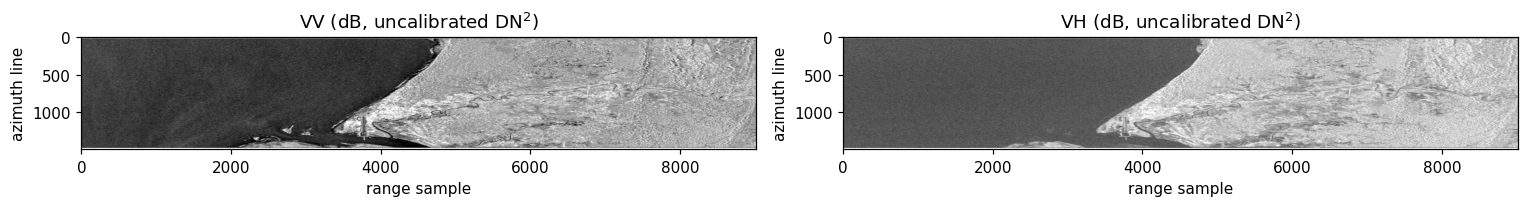

In [3]:
# Steps 5 and 6. covariance_c2 box-averages |VV|², |VH|² and VV·conj(VH) together, so the
# multilook and the 2×2 covariance matrix are one call. The average keeps the single-look
# grid (one value per SLC pixel); it does not thin the array.

# 1. Three azimuth lines by 18 range samples. A single-look pixel here is about 14 m by 2.3 m,
#    so the window is about 42 m by 42 m on the ground: 54 looks, and close to square.
#    This is a plain box mean. The edge-preserving alternative is sar.speckle.refined_lee,
#    applied the same way to c11, c22, c12_re and c12_im.
LOOKS = (3, 18)   # (azimuth, range) box, ~42 m x 42 m on the ground, 54 looks
# dual-pol covariance matrix C2 (c11, c22 and the cross term c12), averaged over LOOKS
c2 = sar.covariance_c2(vv, vh, LOOKS)
# c11 = <|VV|²>, c22 = <|VH|²>, and (c12_re, c12_im) = <VV·conj(VH)>. span is their total
# power. The decompositions below split this same quantity into mechanisms.
span = c2["c11"] + c2["c22"]
# grid size and ground cell size
print(f"C2 grid: {c2['c11'].shape}, ground cell {LOOKS[0] * ann_vv['azimuth_pixel_spacing']:.0f} m x "
      f"{LOOKS[1] * ann_vv['range_pixel_spacing']:.0f} m ({LOOKS[0] * LOOKS[1]} looks)")

# 2. The two intensities in dB. These are uncalibrated digital numbers (the burst calibration
#    LUT is not applied), so the colour scale is DN², not sigma-nought. VV, the co-pol
#    channel, is the brighter of the two over this coast.
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].imshow(10 * np.log10(c2["c11"]), cmap="gray", vmin=30, vmax=48)  # VV power in dB
axes[0].set_title("VV (dB, uncalibrated DN$^2$)")  # title
axes[1].imshow(10 * np.log10(c2["c22"]), cmap="gray", vmin=20, vmax=40)  # VH power in dB
axes[1].set_title("VH (dB, uncalibrated DN$^2$)")  # title
for ax in axes:  # for both panels
    ax.set_xlabel("range sample"); ax.set_ylabel("azimuth line")  # axis labels
plt.tight_layout()  # arrange

### H/alpha, Stokes parameters, and the three model-based decompositions

`h_alpha_dual` gives entropy, anisotropy and mean alpha from the C2 eigendecomposition, plus
DpRVI. `stokes_parameters` treats {VV, VH} as a hybrid-pol-style Stokes vector (Raney 2007) to
get the degree of polarization `m` directly. `m_delta_decomposition` and `m_chi_decomposition`
split the span into surface/double-bounce/volume power using the co-cross relative phase and
an ellipticity-style angle respectively; `dual_pol_model_decomposition` does the same split
using the eigen-decomposition's mean alpha instead, in the spirit of the dual-pol model-based
decompositions of Mascolo et al. (2022). All three conserve power exactly:
`ps + pd + pv == span`.


In [4]:
# Step 8. Five readings of the same C2 matrix. **c2 passes its four elements
# (c11, c22, c12_re, c12_im) as the arguments of each function below.

# 1. h_alpha_dual is the Cloude (2007) dual-pol eigen-decomposition: entropy (0-1),
#    anisotropy, mean alpha in degrees, both eigenvalues, and DpRVI (Mandal et al. 2020).
ha = sar.h_alpha_dual(**c2)
# stokes_parameters treats {VV, VH} as a hybrid-pol Stokes vector (Raney 2007). s0 is the
# span. degree_of_polarization is 0 for fully depolarized return and 1 for one pure
# mechanism; on a 2×2 Hermitian matrix it equals the anisotropy.
st = sar.stokes_parameters(**c2)
# m-δ splits the span with the co/cross relative phase. Surface power grows as that phase
# nears 0°, double-bounce as it nears 180°, and the depolarized remainder is volume.
md = sar.m_delta_decomposition(**c2)
# m-χ uses an ellipticity angle instead of the relative phase. Surface is largest near
# χ = −45° and double-bounce near +45°; volume is again the depolarized part of the span.
mc = sar.m_chi_decomposition(**c2)
# The eigen model gives the depolarized part of the span to volume, then the polarized
# remainder entirely to surface when mean alpha is under 45° and entirely to double-bounce
# when it is not (the dual-pol model-based split of Mascolo et al. 2022).
dm = sar.dual_pol_model_decomposition(**c2)

# 2. Each decomposition is built so ps + pd + pv equals the span. The number printed is the
#    largest relative leftover, over real NaN-padded float32 data rather than the algebra.
for name, out in (("m-delta", md), ("m-chi", mc), ("eigen model", dm)):
    # surface + double-bounce + volume power should add up to the total power (span)
    rel_err = np.nanmax(np.abs((out["ps"] + out["pd"] + out["pv"]) - span) / np.maximum(span, 1e-6))
    print(f"{name:12s} max relative power-conservation error: {rel_err:.2e}")  # largest relative error

# 3. Scene means. A power share is that mechanism's mean power divided by the mean span,
#    in percent. The three splits need not agree: they attribute the same two channels
#    to surface, double-bounce and volume by different rules.
summary = pd.DataFrame({
    "entropy": [np.nanmean(ha["entropy"])], "anisotropy": [np.nanmean(ha["anisotropy"])],
    "mean alpha (deg)": [np.nanmean(ha["alpha"])], "DpRVI": [np.nanmean(ha["dprvi"])],
    "degree of polarization": [np.nanmean(st["degree_of_polarization"])],
    "m-delta Ps/Pd/Pv (%)": [tuple(round(100 * np.nanmean(md[k]) / np.nanmean(span), 1) for k in ("ps", "pd", "pv"))],
    "model Ps/Pd/Pv (%)": [tuple(round(100 * np.nanmean(dm[k]) / np.nanmean(span), 1) for k in ("ps", "pd", "pv"))],
}, index=["scene mean"]).T
summary  # show the summary table

m-delta      max relative power-conservation error: 1.59e-07
m-chi        max relative power-conservation error: 1.59e-07


eigen model  max relative power-conservation error: 8.20e-08


,scene mean
entropy,0.60671
anisotropy,0.679304
mean alpha (deg),18.382763
DpRVI,0.424276
degree of polarization,0.679304
m-delta Ps/Pd/Pv (%),"(70.4, 0.7, 28.9)"
model Ps/Pd/Pv (%),"(71.1, 0.0, 28.9)"


Mean alpha sits well under 45 degrees and all three decompositions put most of the scene's
power in `pv` (diffuse/volume-like) -- expected for a crop that is mostly coastline, aquaculture
ponds and cropland rather than dense city blocks. Degree of polarization, m, is below 1 but well
above 0: a mix of fairly deterministic return (smooth water, bare mudflats) with noisier, more
depolarizing patches (vegetation, rougher ground). The three decompositions do not agree exactly
on how much double-bounce power `pd` there is (m-delta's phase-based estimate is 0.7%, the
eigen-alpha model's is under 0.05%) -- a reminder that these are three different, non-equivalent
ways of attributing the same two-channel measurement to physical mechanisms, not three
measurements of one ground truth.

#### The H-alpha plane

Plotting every pixel's entropy against its mean alpha, with the Cloude-Pottier zone boundaries
drawn in, is the usual way to see the mixture of scattering regimes at a glance.


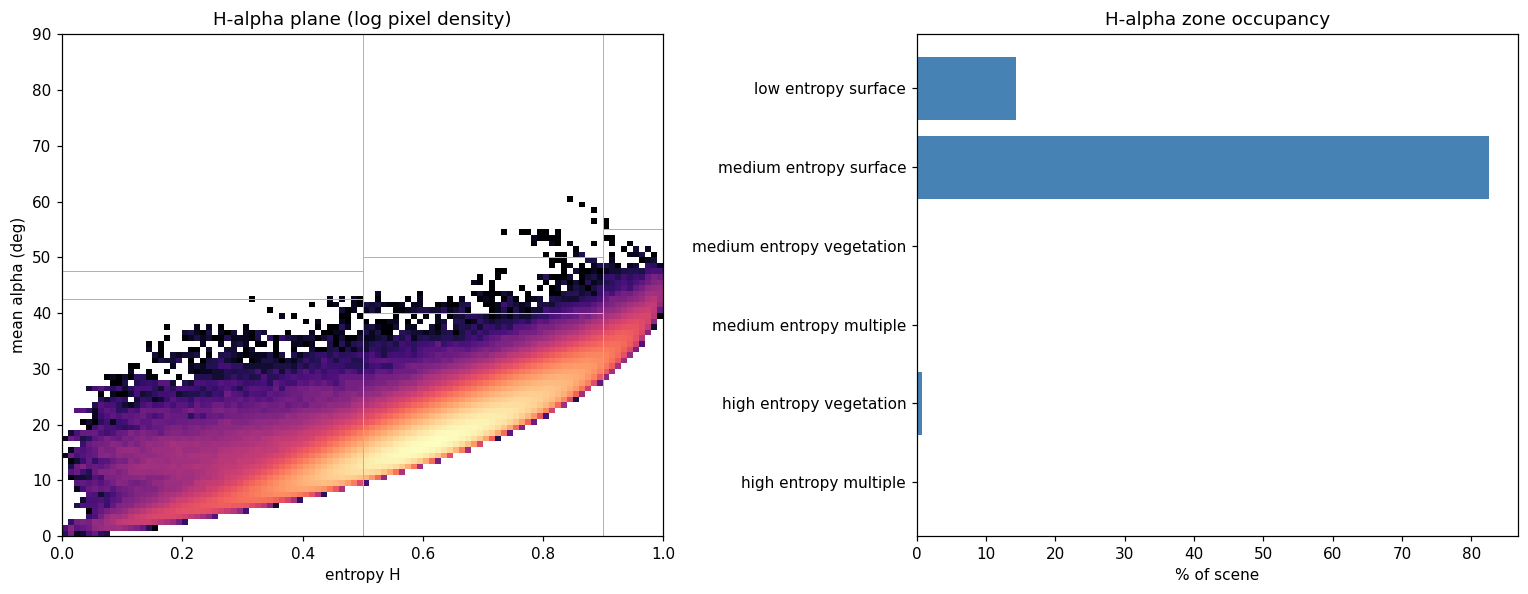

In [5]:
# Every pixel as a point in the H-α plane, then the share of the scene in each
# Cloude-Pottier zone. Low alpha is surface scattering, alpha near 90° is double-bounce,
# and high entropy means the two mechanisms are mixed.

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

# 1. A 2-D histogram of entropy (0-1) against mean alpha (0-90°). LogNorm keeps the dense
#    low-alpha cloud from hiding the sparse high-alpha tail. The cyan rectangles are the
#    zone boundaries stored on H_ALPHA_ZONES (Z3, high-entropy surface, is omitted).
h, a = np.ravel(ha["entropy"]), np.ravel(ha["alpha"])
ok = np.isfinite(h) & np.isfinite(a)  # pixels with valid entropy and alpha
# 2-D histogram of the H-alpha plane
axes[0].hist2d(h[ok], a[ok], bins=(100, 90), range=[[0, 1], [0, 90]], cmap="magma",
              norm=plt.matplotlib.colors.LogNorm())
for (h0, h1), (a0, a1) in sar.polsar.H_ALPHA_ZONES.values():  # each zone of the H-alpha plane
    axes[0].plot([h0, h1, h1, h0, h0], [a0, a0, a1, a1, a0], color="cyan", lw=0.6)  # draw its outline
# labels and title
axes[0].set(xlabel="entropy H", ylabel="mean alpha (deg)", title="H-alpha plane (log pixel density)")

# 2. h_alpha_classify returns a zone code 1-9 per pixel, or 0 where the pixel sits just
#    outside every zone (the boundaries do not tile the whole plane). The bar labels drop
#    the "Z9" prefix. Pixels with no entropy are left out, and so is that code-0 remainder.
zones = sar.h_alpha_classify(xr.DataArray(ha["entropy"]), xr.DataArray(ha["alpha"])).values
# zone number -> zone name
zone_names = {v: k.split(" ", 1)[1] for k, (_, _) in sar.polsar.H_ALPHA_ZONES.items()
             for v in [int(k[1])]}
pix = zones[np.isfinite(ha["entropy"])]  # zone of every valid pixel
counts = pd.Series(pix).value_counts(normalize=True).sort_index() * 100  # share of pixels in each zone (%)
counts = counts[counts.index > 0]   # drop the <3% of pixels that fall just outside every zone boundary
# horizontal bar chart
axes[1].barh([zone_names.get(i, str(i)) for i in counts.index], counts.values, color="steelblue")
axes[1].set(xlabel="% of scene", title="H-alpha zone occupancy")  # labels and title
plt.tight_layout()  # arrange

### A closer look: double-bounce near Cox's Bazar airport

Zooming into the airport perimeter (built structures, hard standing, perimeter fencing) shows
why alpha and the model-based `pd` term are worth having even with only two channels: the
bright, speckled texture in VV lines up with small but real patches of alpha > 45 degrees and
a red (double-bounce) tint in the surface/volume/double-bounce composite below, right where the
built structures are -- while the surrounding cropland and the diagonal road/embankment running
through the scene stay green (volume) and blue (surface).


double-bounce-dominated (alpha > 45 deg) pixels in this crop: 0.17%, vs 0.005% over the whole scene


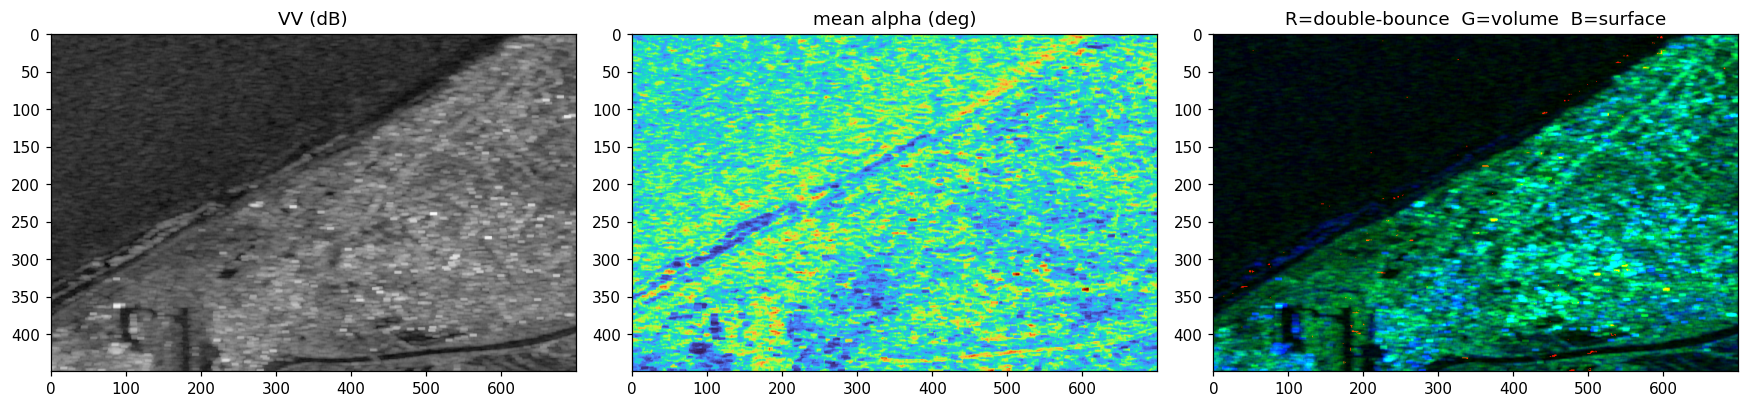

In [6]:
# A finer C2 over the airport. Less averaging keeps the built structures from being
# mixed into the cropland around them.

# 1. Half the range looks of the scene-wide window: 3 lines by 9 samples, about 42 m by
#    21 m. Entropy, alpha and the eigen-model powers are recomputed on that grid.
c2_fine = sar.covariance_c2(vv, vh, (3, 9))
ha_fine = sar.h_alpha_dual(**c2_fine)  # H-alpha decomposition at the finer looks
dm_fine = sar.dual_pol_model_decomposition(**c2_fine)  # model-based decomposition at the finer looks

# 2. Rows and columns in the single-look array, around the airport perimeter
#    (buildings, hard standing, fencing).
r0, r1, c0, c1 = 700, 1150, 3600, 4300   # window-relative rows/cols around the airport


def stretch(x, lo=2, hi=98):  # 2-98 % stretch to [0, 1]
    # Map one band onto 0-1 between its 2nd and 98th percentiles, so a single bright
    # building does not wash the rest of the composite out to white.
    a, b = np.nanpercentile(x, [lo, hi])
    return np.nan_to_num(np.clip((x - a) / (b - a), 0, 1))  # clipped and NaN-free


# 3. Square-root power, then the percentile stretch. Red is double-bounce (pd), green is
#    volume (pv) and blue is surface (ps).
rgb = np.dstack([stretch(np.sqrt(dm_fine["pd"][r0:r1, c0:c1])),
                 stretch(np.sqrt(dm_fine["pv"][r0:r1, c0:c1])),
                 stretch(np.sqrt(dm_fine["ps"][r0:r1, c0:c1]))])

# 4. VV intensity, mean alpha, and the three-colour composite of this crop.
fig, axes = plt.subplots(1, 3, figsize=(16, 6))
axes[0].imshow(10 * np.log10(c2_fine["c11"][r0:r1, c0:c1]), cmap="gray")  # VV in dB, cropped
axes[0].set_title("VV (dB)")  # title
axes[1].imshow(ha_fine["alpha"][r0:r1, c0:c1], cmap="turbo", vmin=0, vmax=60)  # mean alpha, cropped
axes[1].set_title("mean alpha (deg)")  # title
axes[2].imshow(rgb)  # RGB composite of the decomposition powers
axes[2].set_title("R=double-bounce  G=volume  B=surface")  # title
plt.tight_layout()  # arrange

# 5. Share of this crop with alpha above 45° (double-bounce in the eigen model), set
#    against the same share over the whole scene.
frac_db = np.nanmean(ha_fine["alpha"][r0:r1, c0:c1] > 45) * 100
# share of double-bounce pixels
print(f"double-bounce-dominated (alpha > 45 deg) pixels in this crop: {frac_db:.2f}%, "
      f"vs {np.nanmean(ha['alpha'] > 45) * 100:.3f}% over the whole scene")

### Terrain correction

Finally, geocode entropy, mean alpha, VV and the model-decomposition volume fraction onto the
Copernicus GLO-30 DEM's map grid (the same DEM tile already cached by the GRD tutorial), using
the burst's own (non-precise) orbit state vectors and `geo2rdr`/`terrain_correct` -- the same
range-Doppler geocoding the InSAR notebooks use, just for one date instead of a stack.


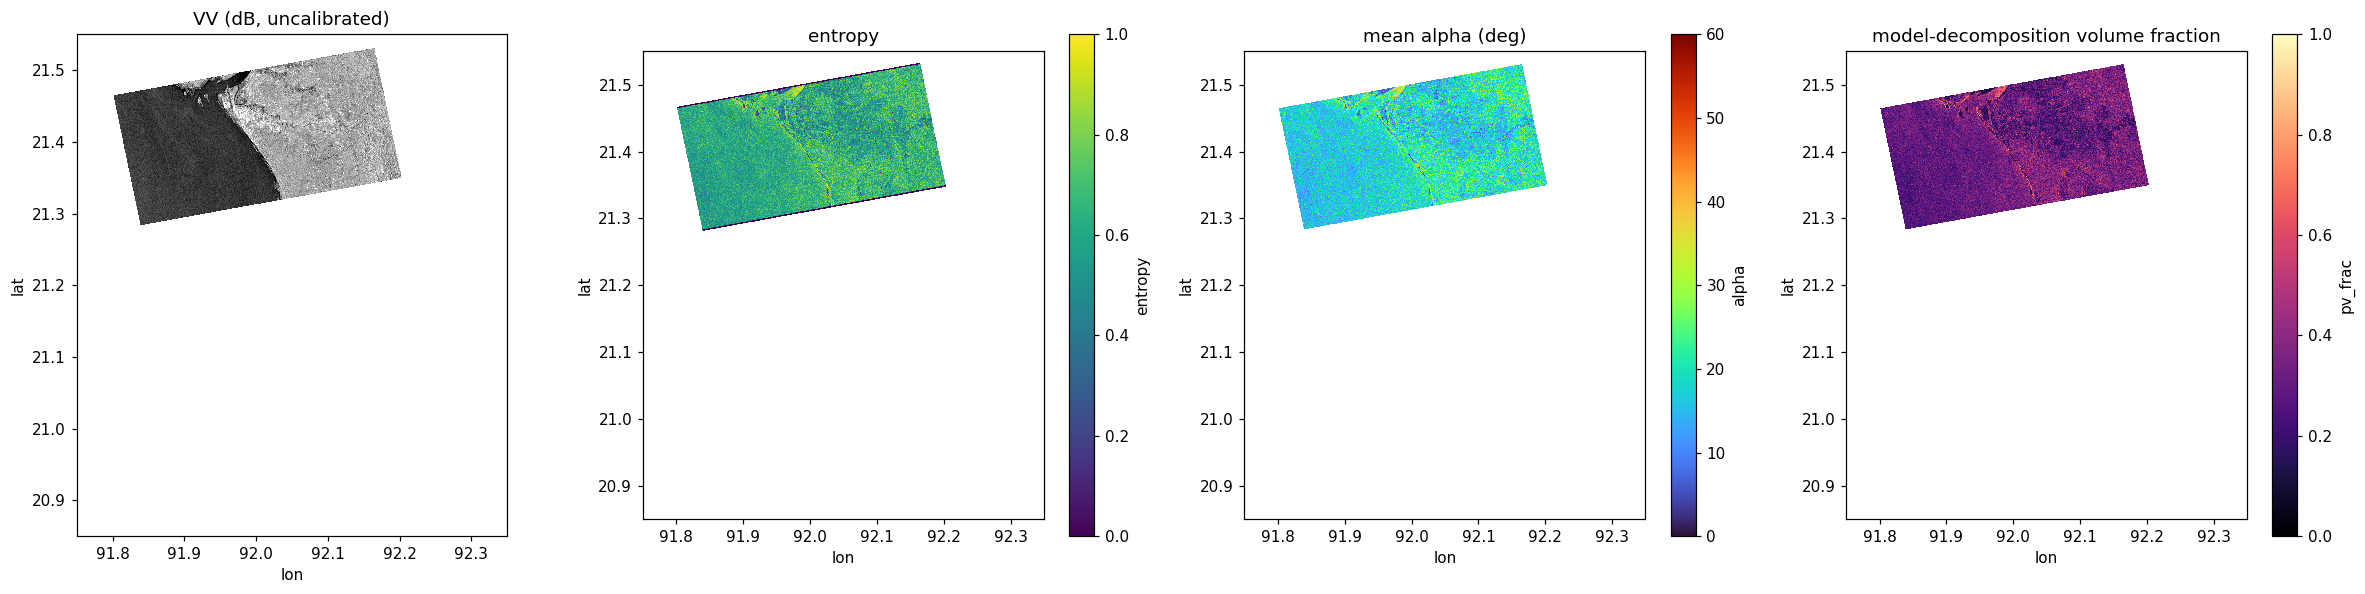

In [7]:
# Step 9. Geocode the radar-grid layers onto the Copernicus DEM. The orbit is the
# annotation's own restituted state vectors (no POEORB file); that is enough to place
# pixels to within a DEM cell or two on this overview map.

# 1. The DEM tile cached by the GRD tutorial. terrain_correct uses these heights to put
#    each map cell into radar geometry, which removes foreshortening and layover.
dem = rioxarray.open_rasterio(DEM_PATH).squeeze(drop=True)

# 2. Zero-Doppler time of every azimuth line, and the slant range of the first kept
#    sample. slant_range_time is the two-way travel time of sample 0 of the full burst;
#    c/2 turns that into a range, and COL0 · range spacing shifts it to the AOI crop.
#    The C2 grid was only box-averaged, so it still has one value per single-look pixel
#    and lines up with these times and this near range.
lpb = ann_vv["lines_per_burst"]
t0 = ann_vv["bursts"][BURST_INDEX]["azimuth_time"]  # azimuth time of the first line of the burst
# azimuth time of every line
az_time = t0 + (np.arange(lpb) * ann_vv["azimuth_time_interval"] * 1e9).astype("timedelta64[ns]")
# slant range of the first column
near_range = ann_vv["slant_range_time"] * sar.SPEED_OF_LIGHT / 2 + COL0 * ann_vv["range_pixel_spacing"]

# 3. Four layers, sampled at every DEM cell by range-Doppler (geo2rdr inside
#    terrain_correct). vv_db and the volume fraction are derived here; entropy and alpha
#    come from the scene-wide decomposition. pv / span is the model's volume share.
geo = sar.terrain_correct(
    {"vv_db": (10 * np.log10(c2["c11"])).astype("float32"),
     "entropy": ha["entropy"].astype("float32"),
     "alpha": ha["alpha"].astype("float32"),
     "pv_frac": (dm["pv"] / span).astype("float32")},
    az_time, near_range, ann_vv["range_pixel_spacing"], ann_vv["orbit"], dem,
)

# 4. The same four layers in map coordinates. VV is still uncalibrated DN². Equal aspect
#    keeps degrees of longitude and latitude from stretching the coast.
fig, axes = plt.subplots(1, 4, figsize=(22, 5.5))
geo["vv_db"].plot(ax=axes[0], cmap="gray", vmin=30, vmax=48, add_colorbar=False)  # geocoded VV
axes[0].set_title("VV (dB, uncalibrated)")  # title
geo["entropy"].plot(ax=axes[1], cmap="viridis", vmin=0, vmax=1)  # geocoded entropy
axes[1].set_title("entropy")  # title
geo["alpha"].plot(ax=axes[2], cmap="turbo", vmin=0, vmax=60)  # geocoded mean alpha
axes[2].set_title("mean alpha (deg)")  # title
geo["pv_frac"].plot(ax=axes[3], cmap="magma", vmin=0, vmax=1)  # geocoded volume fraction
axes[3].set_title("model-decomposition volume fraction")  # title
for ax in axes:  # for every panel
    ax.set_aspect("equal"); ax.set_xlabel("lon"); ax.set_ylabel("lat")  # equal aspect and axis labels
plt.tight_layout()  # arrange

## Takeaways and limitations

- With only VV and VH, `geolattice.rsense.sar.polsar` recovers entropy, anisotropy, mean alpha,
  degree of polarization and three different surface/double-bounce/volume power splits from a
  single real Sentinel-1 acquisition -- no HH/HV needed.
- Over this coastal/agricultural crop, scattering is overwhelmingly low-alpha and
  volume/surface dominated (median alpha well under 45 degrees, double-bounce power a
  fraction of a percent scene-wide); the exception is the built-up fringe around Cox's Bazar
  airport, where alpha and the model-decomposition's `pd` term both pick out the same patches
  the VV backscatter highlights as bright and textured -- a real double-bounce signal, localised
  exactly where urban/dihedral structures actually are.
- **What would make this more rigorous:** per-channel radiometric calibration of the burst
  (needs a calibration-XML reader that isolates the right `<product>` block in ASF's combined
  burst-extractor metadata -- not yet in `geolattice`); a precise POEORB orbit for the terrain
  correction (not needed for the phase-free intensity work here, but cheap to add the same way
  the InSAR notebooks do); and, if HH/HV ever becomes available over the same scene, a true
  quad-pol decomposition (Freeman-Durden, Yamaguchi, Cloude-Pottier H/A/alpha on T3) for a direct
  comparison against the dual-pol approximations used here.

#### References

- Cloude, S. R. (2007). *The dual polarization entropy/alpha decomposition: A PALSAR case
  study.* Proc. 3rd Intl Workshop POLinSAR.
- Mandal, D., Kumar, V., Ratha, D., Dey, S., Bhattacharya, A., Lopez-Sanchez, J. M.,
  McNairn, H., & Rao, Y. S. (2020). *Dual polarimetric radar vegetation index for crop growth
  monitoring using Sentinel-1 SAR data.* Remote Sensing of Environment, 247, 111954.
- Raney, R. K. (2007). *Hybrid-polarity SAR architecture.* IEEE TGRS, 45(11), 3397-3404.
- Charbonneau, F. J., Brisco, B., Raney, R. K., McNairn, H., Liu, C., Vachon, P. W., Shang, J.,
  DeAbreu, R., Champagne, C., Merzouki, A., & Geldsetzer, T. (2010). *Compact polarimetry
  overview for hybrid dual-polarized SAR data.* Canadian Journal of Remote Sensing, 36(sup2),
  S298-S315.
- Mascolo, L., Cloude, S. R., & Lopez-Sanchez, J. M. (2022). *Model-based decomposition of
  dual-pol SAR data: Application to Sentinel-1.* IEEE TGRS, 60, 1-13.
